In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv


# Voting Ensemble Learning

## Introduction

Voting Ensemble Learning is an Ensemble Machine Learning technique
that combines predictions from multiple individual ML models to
produce a final prediction.

Instead of depending on a single model, Voting combines multiple
models and uses their collective predictions to make a decision.

It follows the principle of **Wisdom of the Crowd**, which suggests
that combining multiple independent opinions can produce a more
reliable result than depending on a single opinion.

### Example

Suppose we want to predict whether an email is Spam or Not Spam.

We train three different ML models:

- Logistic Regression → Spam
- Decision Tree → Spam
- KNN → Not Spam

The final prediction will be Spam because the majority of models
predicted Spam.

This process is called Voting.

In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Ensemble Learning
from sklearn.ensemble import VotingClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

In [3]:
# Load dataset
df = pd.read_csv('/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv')

# Display first five rows
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
print("Dataset Shape:", df.shape)
df.info()
df.describe()
df.isnull().sum()

Dataset Shape: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  p

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [5]:
df.drop(columns=['id', 'Unnamed: 32'], inplace=True, errors='ignore')

df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


diagnosis
B    357
M    212
Name: count, dtype: int64


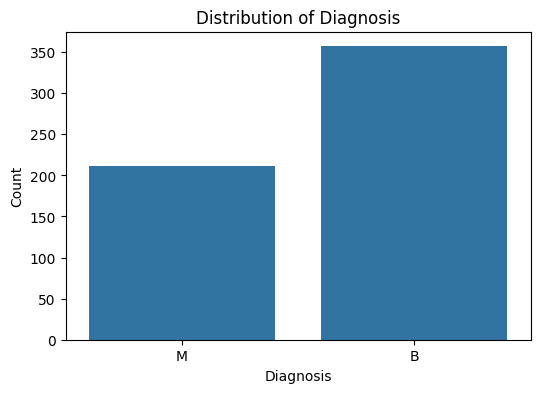

In [6]:
print(df['diagnosis'].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='diagnosis')

plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

In [7]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis'].map({'M': 1, 'B': 0})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (569, 30)
Target Shape: (569,)

Target Distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)


In [12]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

In [13]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
KNN trained successfully!
SVM trained successfully!
Decision Tree trained successfully!


In [14]:
results = {}

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print(f"{name}: {accuracy:.4f}")

Logistic Regression: 0.9649
KNN: 0.9561
SVM: 0.9737
Decision Tree: 0.9298


In [15]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=['Model', 'Accuracy']
)

results_df.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
2,SVM,0.973684
0,Logistic Regression,0.964912
1,KNN,0.956140
3,Decision Tree,0.929825


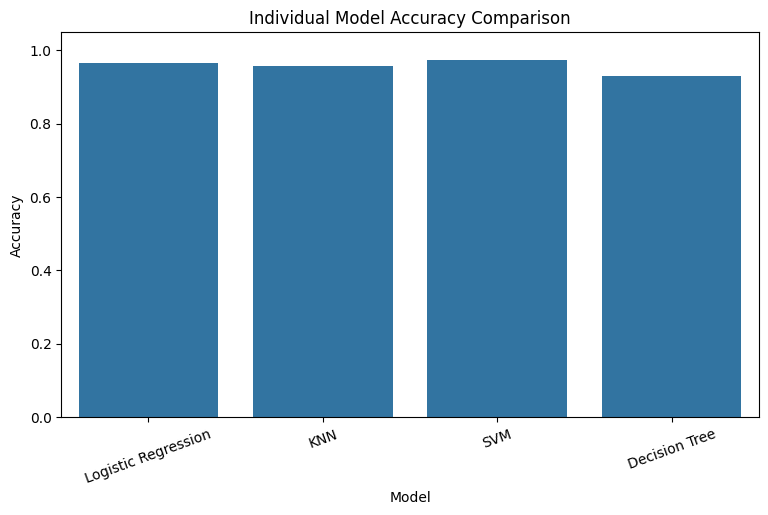

In [16]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Individual Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.show()

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_results = {}

for name, model in models.items():

    pipeline = make_pipeline(
        StandardScaler(),
        model
    )

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring='accuracy'
    )

    cv_results[name] = scores.mean()

    print(f"{name}")
    print("Fold Scores:", np.round(scores, 4))
    print("Mean Accuracy:", round(scores.mean(), 4))
    print("-" * 50)

Logistic Regression
Fold Scores: [0.9825 0.9825 0.9474 0.9474 0.9825 0.9474 1.     0.9825 0.9825 1.    ]
Mean Accuracy: 0.9754
--------------------------------------------------
KNN
Fold Scores: [0.9825 0.9825 0.9649 0.9474 0.9474 0.9474 1.     0.9825 0.9649 0.9821]
Mean Accuracy: 0.9701
--------------------------------------------------
SVM
Fold Scores: [1.     0.9825 0.9474 0.9649 0.9649 0.9649 1.     0.9474 0.9825 1.    ]
Mean Accuracy: 0.9754
--------------------------------------------------
Decision Tree
Fold Scores: [0.9123 0.9298 0.9649 0.8947 0.8947 0.9649 0.9298 0.9123 0.9298 0.9286]
Mean Accuracy: 0.9262
--------------------------------------------------


In [18]:
cv_df = pd.DataFrame(
    list(cv_results.items()),
    columns=['Model', 'Mean CV Accuracy']
)

cv_df.sort_values(
    by='Mean CV Accuracy',
    ascending=False
)

,Model,Mean CV Accuracy
2,SVM,0.975439
0,Logistic Regression,0.975439
1,KNN,0.970144
3,Decision Tree,0.926190


## Step 15: Evaluating Hard Voting Classifier

After training the Hard Voting Classifier, we evaluate it
using the test dataset.

We calculate:

- Accuracy
- Precision
- Recall
- F1-Score

These metrics help us understand how well the ensemble
classifies malignant and benign tumors.

In [19]:
from sklearn.ensemble import VotingClassifier

# Create individual estimators
estimators = [
    ('lr', LogisticRegression(max_iter=1000)),
    ('knn', KNeighborsClassifier(n_neighbors=5)),
    ('svm', SVC(probability=True, random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42))
]

# Create Hard Voting Classifier
hard_voting = VotingClassifier(
    estimators=estimators,
    voting='hard'
)

# Train the model
hard_voting.fit(X_train_scaled, y_train)

print("Hard Voting Classifier trained successfully!")

Hard Voting Classifier trained successfully!


In [20]:
# Predictions
y_pred_hard = hard_voting.predict(X_test_scaled)

# Evaluation
print("Hard Voting Accuracy:", accuracy_score(y_test, y_pred_hard))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_hard))

Hard Voting Accuracy: 0.956140350877193

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        72
           1       1.00      0.88      0.94        42

    accuracy                           0.96       114
   macro avg       0.97      0.94      0.95       114
weighted avg       0.96      0.96      0.96       114



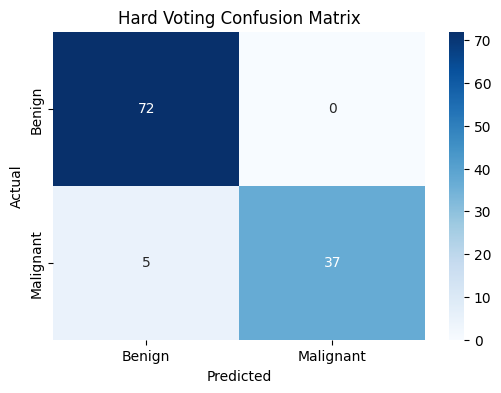

In [21]:
cm = confusion_matrix(y_test, y_pred_hard)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Hard Voting Confusion Matrix")
plt.show()

## Step 17: Soft Voting Classifier

Soft Voting combines the predicted probabilities from all
individual classifiers.

Instead of selecting the majority class based on class labels,
it calculates the average probability for each class.

The class with the highest average probability becomes
the final prediction.

Mathematical Formula:

P(class) = (P1 + P2 + P3 + ... + Pn) / n

Where:
- P1, P2, P3 represent predicted probabilities from individual models.
- n represents the total number of classifiers.

Soft Voting generally works well when individual classifiers
provide reliable probability estimates.

Unlike Hard Voting, Soft Voting requires classifiers that
support probability prediction.

Our SVM already has probability=True.

In [22]:
soft_voting = VotingClassifier(
    estimators=estimators,
    voting='soft'
)

# Train
soft_voting.fit(X_train_scaled, y_train)

# Predict
y_pred_soft = soft_voting.predict(X_test_scaled)

print("Soft Voting Accuracy:", accuracy_score(y_test, y_pred_soft))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_soft))

Soft Voting Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [23]:
voting_results = {
    'Hard Voting': accuracy_score(y_test, y_pred_hard),
    'Soft Voting': accuracy_score(y_test, y_pred_soft)
}

voting_df = pd.DataFrame(
    list(voting_results.items()),
    columns=['Voting Technique', 'Accuracy']
)

print(voting_df)

  Voting Technique  Accuracy
0      Hard Voting  0.956140
1      Soft Voting  0.973684


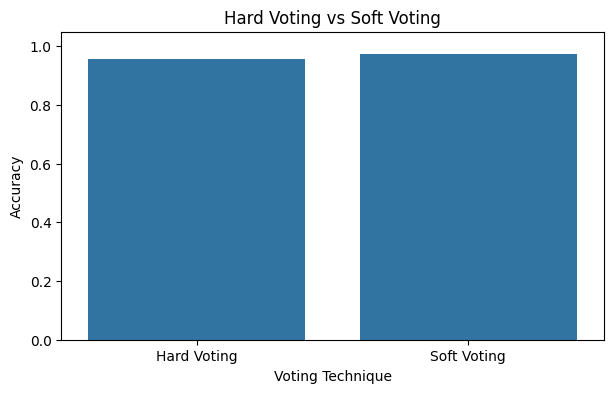

In [24]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=voting_df,
    x='Voting Technique',
    y='Accuracy'
)

plt.title("Hard Voting vs Soft Voting")
plt.ylim(0, 1.05)
plt.show()

In [25]:
weighted_voting = VotingClassifier(
    estimators=estimators,
    voting='soft',
    weights=[2, 1, 3, 1]
)

weighted_voting.fit(X_train_scaled, y_train)

y_pred_weighted = weighted_voting.predict(X_test_scaled)

print("Weighted Soft Voting Accuracy:",
      accuracy_score(y_test, y_pred_weighted))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted))

Weighted Soft Voting Accuracy: 0.9912280701754386

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        72
           1       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



In [28]:
final_results = {}

# Individual models
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    final_results[name] = accuracy_score(y_test, y_pred)

# Ensemble models
final_results['Hard Voting'] = accuracy_score(y_test, y_pred_hard)
final_results['Soft Voting'] = accuracy_score(y_test, y_pred_soft)
final_results['Weighted Soft Voting'] = accuracy_score(y_test, y_pred_weighted)

final_df = pd.DataFrame(
    list(final_results.items()),
    columns=['Model', 'Accuracy']
)

final_df = final_df.sort_values(
    by='Accuracy',
    ascending=False
)

final_df

,Model,Accuracy
6,Weighted Soft Voting,0.991228
5,Soft Voting,0.973684
2,SVM,0.973684
0,Logistic Regression,0.964912
1,KNN,0.956140
4,Hard Voting,0.956140
3,Decision Tree,0.929825


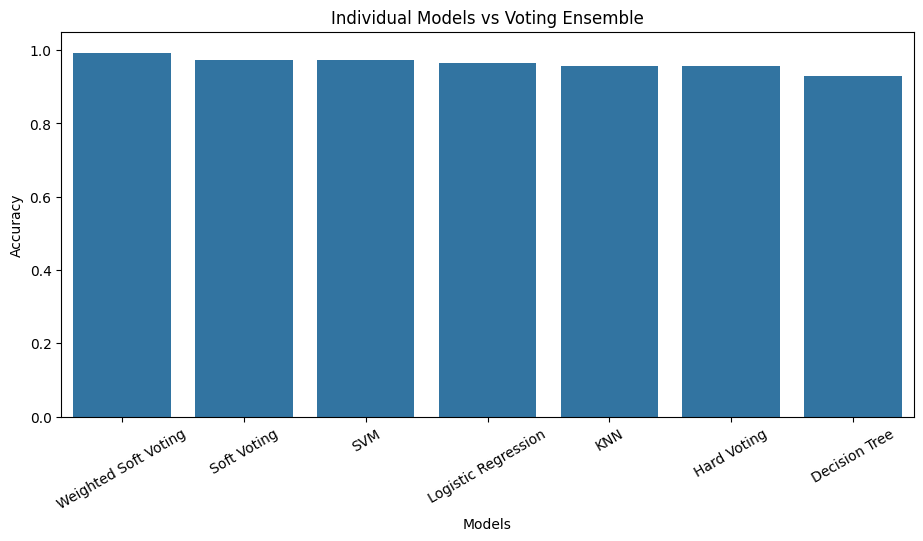

In [29]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=final_df,
    x='Model',
    y='Accuracy'
)

plt.title("Individual Models vs Voting Ensemble")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.ylim(0, 1.05)

plt.show()

## Step 2: Generating Synthetic Regression Dataset

We will generate our own synthetic dataset using Scikit-learn's
make_regression() function.

This function generates artificial numerical data suitable for
regression problems.

### Dataset Configuration

- Number of samples: 1000
- Number of features: 5
- Informative features: 4
- Noise: 20
- Random state: 42

### Parameters

1. n_samples: Number of observations in the dataset.
2. n_features: Number of input features.
3. n_informative: Number of features that actually contribute
   to generating the target.
4. noise: Adds random variation to the target values.
5. random_state: Ensures reproducibility.

Our objective is to predict a continuous numerical target
using multiple regression algorithms.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_regression

# Generate synthetic dataset
X, y = make_regression(
    n_samples=1000,
    n_features=5,
    n_informative=4,
    noise=20,
    random_state=42
)

# Create DataFrame
columns = [
    'Feature_1',
    'Feature_2',
    'Feature_3',
    'Feature_4',
    'Feature_5'
]

df = pd.DataFrame(X, columns=columns)

df['Target'] = y

df.head()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Target
0,-0.457096,-0.027515,1.772252,-0.602212,1.661259,80.546899
1,0.473407,-1.188963,-0.049880,0.290947,-1.046121,-52.861534
2,-0.003374,0.778361,-0.551186,-0.170185,-0.818199,-40.312074
3,0.984322,0.234215,1.550500,-0.213989,-0.998354,-9.898189
4,-0.922410,-0.238932,-0.366824,1.615376,-0.391758,-62.386233


In [31]:
print("Dataset Shape:", df.shape)
df.describe()
df.info()
df.isnull().sum()

Dataset Shape: (1000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature_1  1000 non-null   float64
 1   Feature_2  1000 non-null   float64
 2   Feature_3  1000 non-null   float64
 3   Feature_4  1000 non-null   float64
 4   Feature_5  1000 non-null   float64
 5   Target     1000 non-null   float64
dtypes: float64(6)
memory usage: 47.0 KB


Feature_1    0
Feature_2    0
Feature_3    0
Feature_4    0
Feature_5    0
Target       0
dtype: int64

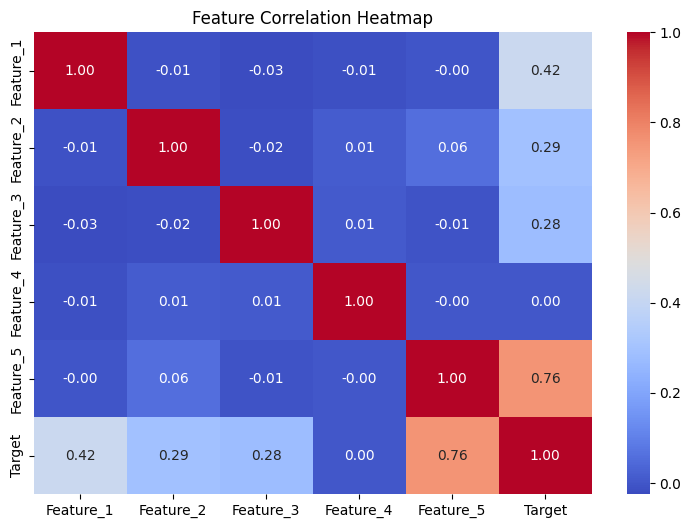

In [32]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

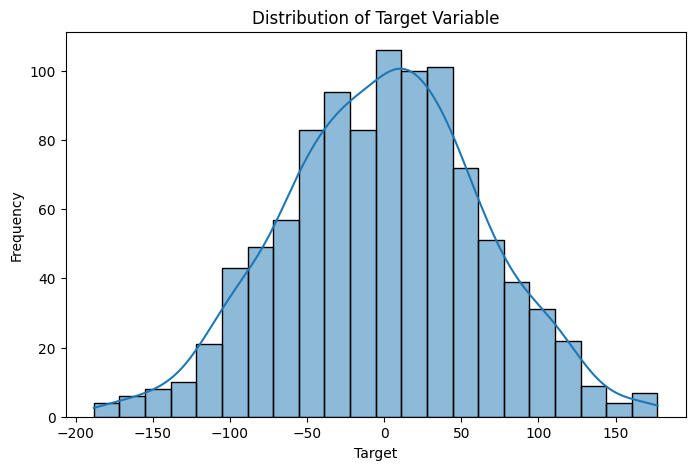

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Target'],
    kde=True
)

plt.title("Distribution of Target Variable")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.show()

In [34]:
X = df.drop('Target', axis=1)

y = df['Target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1000, 5)
Target Shape: (1000,)


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 5)
Testing Features: (200, 5)
Training Target: (800,)
Testing Target: (200,)


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Training Shape: (800, 5)
Testing Shape: (200, 5)


In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'KNN': KNeighborsRegressor(
        n_neighbors=5
    ),

    'SVR': SVR(
        kernel='rbf'
    )
}

In [38]:
for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    print(f"{name} trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
KNN trained successfully!
SVR trained successfully!


In [39]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = {}

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results[name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))


Linear Regression
MAE: 15.1798
MSE: 382.4864
RMSE: 19.5573
R2 Score: 0.9183

Decision Tree
MAE: 25.572
MSE: 1075.143
RMSE: 32.7894
R2 Score: 0.7704

KNN
MAE: 21.2431
MSE: 722.5099
RMSE: 26.8795
R2 Score: 0.8457

SVR
MAE: 32.7102
MSE: 2077.8503
RMSE: 45.5834
R2 Score: 0.5563


In [40]:
results_df = pd.DataFrame(results).T

results_df.sort_values(
    by='R2 Score',
    ascending=False
)

,MAE,MSE,RMSE,R2 Score
Linear Regression,15.179849,382.486394,19.557259,0.918320
KNN,21.243106,722.509898,26.879544,0.845708
Decision Tree,25.571993,1075.142964,32.789373,0.770403
SVR,32.710231,2077.850347,45.583444,0.556274


In [41]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_results = {}

for name, model in models.items():

    pipeline = make_pipeline(
        StandardScaler(),
        model
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='r2'
    )

    cv_results[name] = scores.mean()

    print(f"\n{name}")
    print("Fold Scores:", np.round(scores, 4))
    print("Mean R2 Score:", round(scores.mean(), 4))
    print("-" * 50)


Linear Regression
Fold Scores: [0.8832 0.8664 0.8865 0.9382 0.8961 0.8972 0.9049 0.8848 0.8846 0.8885]
Mean R2 Score: 0.893
--------------------------------------------------

Decision Tree
Fold Scores: [0.6336 0.6156 0.6394 0.7854 0.6208 0.6093 0.7063 0.6756 0.6479 0.706 ]
Mean R2 Score: 0.664
--------------------------------------------------

KNN
Fold Scores: [0.8034 0.8343 0.774  0.8506 0.7809 0.8023 0.8184 0.7971 0.793  0.8278]
Mean R2 Score: 0.8082
--------------------------------------------------

SVR
Fold Scores: [0.4953 0.5845 0.5195 0.5444 0.4613 0.5667 0.5288 0.519  0.5584 0.5589]
Mean R2 Score: 0.5337
--------------------------------------------------


In [42]:
cv_df = pd.DataFrame(
    list(cv_results.items()),
    columns=['Model', 'Mean CV R2']
)

cv_df.sort_values(
    by='Mean CV R2',
    ascending=False
)

,Model,Mean CV R2
0,Linear Regression,0.893042
2,KNN,0.808195
1,Decision Tree,0.663993
3,SVR,0.533684


In [43]:
from sklearn.ensemble import VotingRegressor

estimators = [
    ('lr', LinearRegression()),

    ('dt', DecisionTreeRegressor(
        random_state=42
    )),

    ('knn', KNeighborsRegressor(
        n_neighbors=5
    )),

    ('svr', SVR(
        kernel='rbf'
    ))
]

voting_reg = VotingRegressor(
    estimators=estimators
)

# Train Voting Regressor
voting_reg.fit(X_train_scaled, y_train)

print("Voting Regressor trained successfully!")

Voting Regressor trained successfully!


In [44]:
y_pred_voting = voting_reg.predict(X_test_scaled)

print("Voting Regressor Evaluation")

print("MAE:",
      mean_absolute_error(y_test, y_pred_voting))

print("MSE:",
      mean_squared_error(y_test, y_pred_voting))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_voting)))

print("R2 Score:",
      r2_score(y_test, y_pred_voting))

Voting Regressor Evaluation
MAE: 19.95064357657104
MSE: 675.3247114183935
RMSE: 25.987010436339027
R2 Score: 0.8557841421378883


In [45]:
weighted_voting = VotingRegressor(
    estimators=estimators,
    weights=[2, 1, 2, 3]
)

weighted_voting.fit(X_train_scaled, y_train)

y_pred_weighted = weighted_voting.predict(X_test_scaled)

print("Weighted Voting Regressor")

print("MAE:",
      mean_absolute_error(y_test, y_pred_weighted))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_weighted)))

print("R2 Score:",
      r2_score(y_test, y_pred_weighted))

Weighted Voting Regressor
MAE: 21.203568492961104
RMSE: 28.09501517217744
R2 Score: 0.8314382940550785


In [46]:
dt_estimators = [
    ('dt1', DecisionTreeRegressor(max_depth=2, random_state=42)),
    ('dt2', DecisionTreeRegressor(max_depth=3, random_state=42)),
    ('dt3', DecisionTreeRegressor(max_depth=4, random_state=42)),
    ('dt4', DecisionTreeRegressor(max_depth=5, random_state=42))
]

dt_voting = VotingRegressor(
    estimators=dt_estimators
)

dt_voting.fit(X_train_scaled, y_train)

y_pred_dt = dt_voting.predict(X_test_scaled)

print("Multiple Decision Trees Voting Regressor")

print("MAE:", mean_absolute_error(y_test, y_pred_dt))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))

print("R2 Score:", r2_score(y_test, y_pred_dt))

Multiple Decision Trees Voting Regressor
MAE: 30.46008462428357
RMSE: 38.60510370964387
R2 Score: 0.681734309923201


In [47]:
final_models = {
    'Linear Regression': models['Linear Regression'],
    'Decision Tree': models['Decision Tree'],
    'KNN': models['KNN'],
    'SVR': models['SVR'],
    'Voting Regressor': voting_reg,
    'Weighted Voting': weighted_voting,
    'Multiple Decision Trees': dt_voting
}

final_results = {}

for name, model in final_models.items():

    y_pred = model.predict(X_test_scaled)

    final_results[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2 Score': r2_score(y_test, y_pred)
    }

final_df = pd.DataFrame(final_results).T

final_df.sort_values(
    by='R2 Score',
    ascending=False
)

,MAE,RMSE,R2 Score
Linear Regression,15.179849,19.557259,0.918320
Voting Regressor,19.950644,25.987010,0.855784
KNN,21.243106,26.879544,0.845708
Weighted Voting,21.203568,28.095015,0.831438
Decision Tree,25.571993,32.789373,0.770403
Multiple Decision Trees,30.460085,38.605104,0.681734
SVR,32.710231,45.583444,0.556274


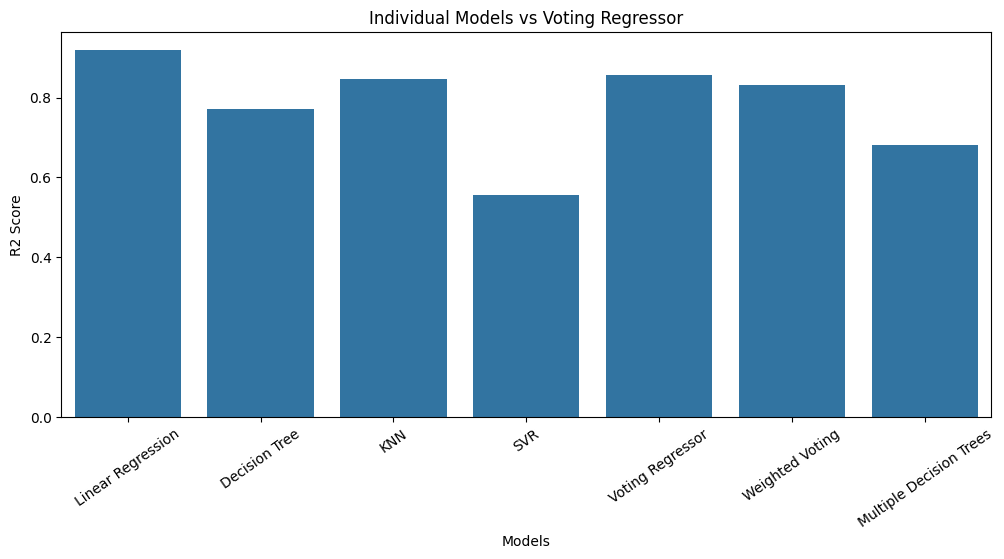

In [48]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=final_df.index,
    y=final_df['R2 Score']
)

plt.title("Individual Models vs Voting Regressor")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=35)
plt.show()

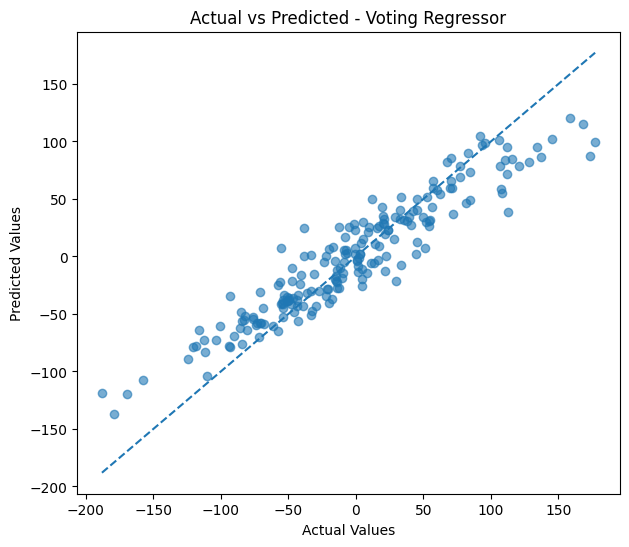

In [49]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_voting,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Voting Regressor")

plt.show()